# Previsão por uti

A série conta só as internações com pelo menos um dia em `UTI_MES_TO`. Também é um subconjunto, não uma parte que soma o total.

O treino segue o da página: julho de 2008 a julho de 2026, nos 27 estados. A LSTM e o TFT preveem agosto de 2026 a julho de 2027. A âncora é o mesmo mês do ano anterior. Agosto e setembro de 2026 não entram, porque a cobrança ainda está incompleta.

Se a previsão já estiver gravada em `dados/`, o notebook só lê e desenha. Para treinar de novo, mude `REUSAR` para `False`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

from modelos_serie import prever
from quebras import ORDEM, montar, painel

QUEBRA = "uti"
PASTA = Path("dados")
REUSAR = True

longo = montar()
fechado = painel(longo, QUEBRA)
caminho_tft = PASTA / f"previsao_{QUEBRA}_tft.parquet"
caminho_lstm = PASTA / f"previsao_{QUEBRA}_lstm.parquet"
if REUSAR and caminho_tft.exists() and caminho_lstm.exists():
    tft = pd.read_parquet(caminho_tft)
    lstm = pd.read_parquet(caminho_lstm)
    print(f"Previsão reutilizada: {fechado.shape[1]} séries.")
else:
    tft, lstm = prever(fechado, PASTA, QUEBRA)

grupos = ORDEM[QUEBRA]
print("Grupos:", ", ".join(grupos))

Previsão reutilizada: 27 séries.
Grupos: Com UTI


C:\Users\emano\OneDrive\Documentos\doutorado\sus\.venv\Lib\site-packages\pytorch_forecasting\models\base\_base_model.py:30: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


## Minas Gerais

O gráfico usa o estado em que as quebras foram escolhidas. A linha vertical é agosto de 2026, o primeiro mês previsto. A página publica a mesma previsão para os 27 estados.

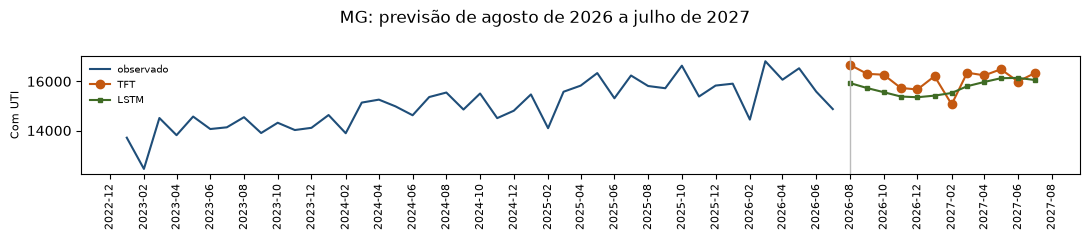

In [2]:
def desenhar(uf: str) -> None:
    n = len(grupos)
    fig, eixos = plt.subplots(n, 1, figsize=(11, 2.4 * n), sharex=True)
    if n == 1:
        eixos = [eixos]
    for eixo, grupo in zip(eixos, grupos):
        coluna = f"{uf}|{grupo}"
        historia = fechado.loc["2023-01-01":, coluna]
        eixo.plot(historia.index, historia, color="#1f4e79", label="observado")
        eixo.plot(tft.index, tft[coluna], color="#c45911", marker="o", label="TFT")
        eixo.plot(lstm.index, lstm[coluna], color="#3f6b24", marker="s", markersize=3, label="LSTM")
        eixo.axvline(pd.Timestamp("2026-08-01"), color="#bbbbbb", linewidth=1)
        eixo.set_ylabel(grupo, fontsize=8)
        eixo.legend(fontsize=7, loc="upper left", frameon=False)
    eixos[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    eixos[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    eixos[-1].tick_params(axis="x", labelrotation=90, labelsize=8)
    fig.suptitle(f"{uf}: previsão de agosto de 2026 a julho de 2027")
    fig.tight_layout()
    fig.savefig(PASTA / f"previsao_{QUEBRA}_{uf}.png", dpi=120, bbox_inches="tight")
    plt.show()

desenhar("MG")